In [2]:
import sys
sys.path.append("..")
from src.io_utils import load_data
df = load_data("../data/health_study_dataset.csv")

In [3]:
%pip install skicit-learn

Note: you may need to restart the kernel to use updated packages.


ERROR: Could not find a version that satisfies the requirement skicit-learn (from versions: none)

[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip
ERROR: No matching distribution found for skicit-learn


[0.50910341 0.25714481 0.15501    0.07874178]


ValueError: Shape of passed values is (4, 4), indices imply (5, 4)

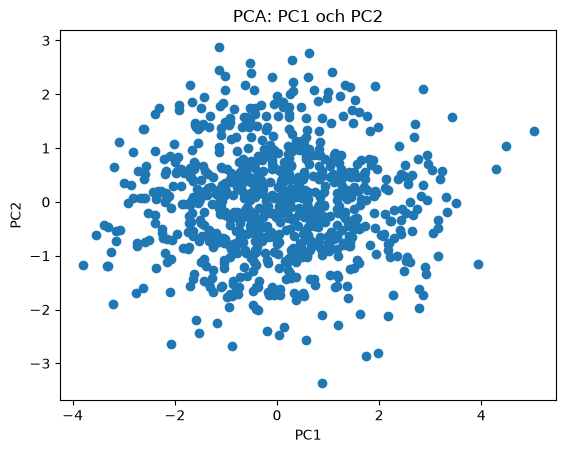

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import seaborn as sns

# KÄLLA: PCA-analys: Ryan # Matt Data Science, PCA Analysis in Python Explained (Scikit - Learn) https://www.youtube.com/watch?v=6uwa9EkUqpg

# 1: VÄLJ VARIABLER
# Vi använder fem numeriska variabler i vår första PCA
X = df[["age", "weight", "systolic_bp", "cholesterol"]]

# Vi lämnar sex, smoker och disease utanför själva PCA-beräkningen
# eftersom vi i första steget vill undersöka hur de fem numeriska variablerna samvarierar

# Vi sparar disease för att senare kunna undersöka om personer med olika PC-värden
# också skiljer sig åt när det gäller sjukdomsförekomst


# 2: STANDARDISERA VARIABLERNA
scaler = StandardScaler()  # Skapar ett objekt av klassen StandardScaler som utför standardiseringen
X_scaled = scaler.fit_transform(X)  # Beräknar medelvärde och standardavvikelse och standardiserar variablerna i X
X_scaled.mean(axis=0)  # Kontrollerar medelvärdet för varje standardiserad variabel
X_scaled.std(axis=0)   # Kontrollerar standardavvikelsen för varje standardiserad variabel
# axis=0 innebär att beräkningen görs nedåt längs raderna, alltså kolumn för kolumn
# axis=1 innebär att beräkningen görs vågrätt längs kolumnerna, alltså rad för rad


# 3: BERÄKNA HUVUDKOMPONENTERNA MED PCA
pca = PCA()  # Skapar ett objekt av klassen PCA som utför huvudkomponentanalysen
# PCA analyserar hur de fem variablerna varierar tillsammans
# Beräkningen bygger på variablernas samvariationsstruktur
# Datorn hittar nya riktningar som fångar så mycket variation i datan som möjligt
# Dessa riktningar blir våra nya variabler, huvudkomponenterna (PC1, PC2 osv)

X_pca = pca.fit_transform(X_scaled)  # Anpassar PCA-modellen och omvandlar datan till huvudkomponenter
# fit_transform() anpassar modellen till datan och omvandlar den i ett steg

# 4: UNDERSÖK RESULTATET
X_pca.shape  # Kontrollerar dimensionerna på resultatet från PCA
print(pca.explained_variance_ratio_) # visar hur stor andel av variationerna varje huvudkomponent (PC) fångar
pca.explained_variance_ratio_.cumsum() # visar ackumulerade (sammanlagda) förklarade variationen.
# PCA1: 0.40914325, PCA1-2: 0.66959189, PCA1-3: 0.83002672, PCA1-4: 0.93826211, PCA1-5: 1
pca.components_ # Visar hur de ursprungliga variablerna bidrar till varje huvudkomponent

# 5. TA FRAM DIAGRAM
# Visualierar personerna i datan utifrån deras två första huvudkomponenter
plt.scatter(X_pca[:, 0], X_pca[:, 1])
# X_pca[:, 0] hämtar PC1-värdena för samtliga 800 personer
# X_pca[:, 1] hämtar PC2-värdena för samtliga 800 personer
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA: PC1 och PC2")
# plt.show()

# KOMMENTAR
# vad positionerna betyder:

# Långt åt höger (högt PC1): Personen har ett högt värde på en kombination 
# som framför allt väger in ålder, blodtryck och kolesterol.

# Långt upp (högt PC2): Personen har ett högt värde på en kombination som 
# framför allt väger in längd och vikt.

pca_components = pd.DataFrame(
    pca.components_,
    columns=X.columns,
    index=["PC1", "PC2", "PC3", "PC4", "PC5"]
).rename_axis("Huvudkomponent")

pc3_components = pd.DataFrame(
    pca.components_,
    columns=X.columns,
    index=["PC1", "PC2", "PC3", "PC4", "PC5"]
).loc["PC3"]

print(pca_components)

X_pca_reduce = X_pca[:, :3] # hämtar PC1-PC3 för samtliga personer
X_pca_reduce.shape

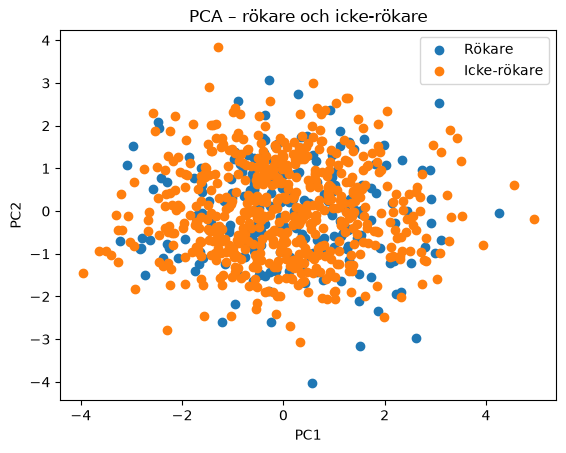

In [ ]:
# 6: JÄMFÖR RÖKARE OCH ICKE-RÖKARE I PCA-DIAGRAMMET
plt.scatter(X_pca[df["smoker"] == "Yes", 0],
            X_pca[df["smoker"] == "Yes", 1],
            label="Rökare")

plt.scatter(X_pca[df["smoker"] == "No", 0],
            X_pca[df["smoker"] == "No", 1],
            label="Icke-rökare")

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA – rökare och icke-rökare")
plt.legend()
plt.show()

# TOLKNING
# Långt åt höger (högt PC1): Personen har ett högt värde på en kombination 
# som framför allt väger in ålder, blodtryck och kolesterol.

# Långt upp (högt PC2): Personen har ett högt värde på en kombination som 
# framför allt väger in längd och vikt.

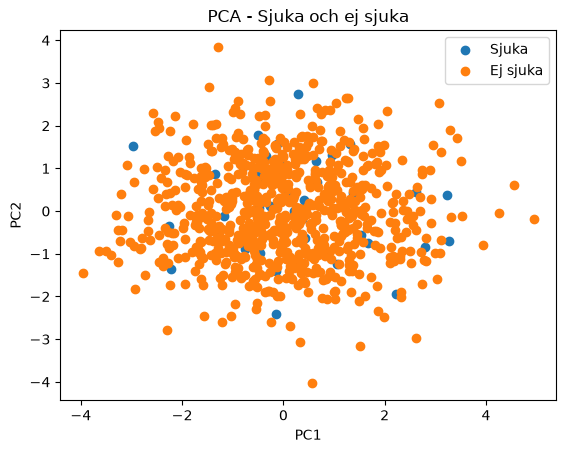

In [ ]:
# 7: JÄMFÖR SJUKA OCH EJ SJUKA I PCA-DIAGRAMMET

plt.scatter(X_pca[df["disease"] == 1, 0],
            X_pca[df["disease"] == 1, 1],
            label="Sjuka")

plt.scatter(X_pca[df["disease"] == 0, 0],
            X_pca[df["disease"] == 0, 1],
            label="Ej sjuka")

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA - Sjuka och ej sjuka")
plt.legend()
plt.show()

# TOLKNING
# Långt åt höger (högt PC1): Personen har ett högt värde på en kombination 
# som framför allt väger in ålder, blodtryck och kolesterol.

# Långt upp (högt PC2): Personen har ett högt värde på en kombination som 
# framför allt väger in längd och vikt.




In [ ]:
# 3D-diagram PCA, sjuka + ej sjuka / rökare + ej rökare

# KÄLLA: https://plotly.com/python/pca-visualization/

import plotly.express as px
from sklearn.decomposition import PCA

# välj variabler
X = df[["age", "height", "weight", "systolic_bp", "cholesterol"]]

# standardisera (variablerna har olika skalor)
scaler = StandardScaler()  # skapar objekt av klassen StandardScaler som utför standardiseringen
X_scaled = scaler.fit_transform(X)  # beräknar medelvärde och standardavvikelse och standardiserar variablerna i X

# beräkna huvudkomponenter med pca
pca = PCA(n_components=3)  # Skapar en PCA-modell som ska ta fram de tre första huvudkomponenterna
X_pca = pca.fit_transform(X_scaled)  # Genomför PCA-beräkningen och räknar om varje persons värden till PC1, PC2 och PC3
# fit: analyserar variablernas samvariation och beräknar huvudkomponenternas riktningar och vikter
# transform: använder dessa riktningar och vikter för att beräkna varje persons PC-värden

# visar andel av den totala variationen som PC1-PC3 tillsammans fångar
total_var = pca.explained_variance_ratio_.sum() * 100

# figur
fig = px.scatter_3d(
    X_pca, x=0, y=1, z=2,
    title=f'Total Explained Variance: {total_var:.2f}%',
    labels={'0': 'PC 1', '1': 'PC 2', '2': 'PC 3'},
    color=df["smoker"]
)

fig.show()

#                    age    height    weight  systolic_bp  cholesterol
# Huvudkomponent                                                        
# PC1             0.573224  0.098300  0.247196     0.568990     0.526209
# PC2            -0.279984  0.693791  0.657227    -0.059119    -0.069424
# PC3             0.277281  0.556410 -0.495263     0.317787    -0.516961

# åt PC1: Personen har ett högt värde på en kombination 
# som framför allt väger in ålder, blodtryck och kolesterol.

# åt PC2: Personen har ett högt värde på en kombination som 
# framför allt väger in längd och vikt

# åt PC3: Personen har ett högt värde på en kombination som 
# framför allt väger in längd och vikt





[0.40914325 0.26044863 0.16043484 0.10823539 0.06173789]
                     age    height    weight  systolic_bp  cholesterol
Huvudkomponent                                                        
PC1             0.573224  0.098300  0.247196     0.568990     0.526209
PC2            -0.279984  0.693791  0.657227    -0.059119    -0.069424
PC3             0.277281  0.556410 -0.495263     0.317787    -0.516961
PC4            -0.142505 -0.432574  0.387781     0.570396    -0.562891
PC5             0.704153 -0.110805  0.333596    -0.496402    -0.366319


(800, 3)

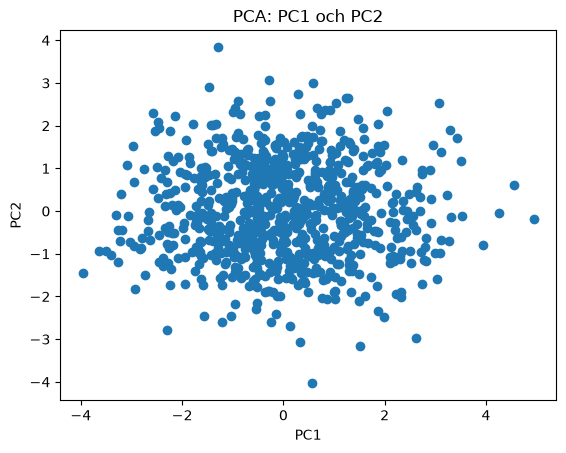

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import seaborn as sns

# KÄLLA: PCA-analys: Ryan # Matt Data Science, PCA Analysis in Python Explained (Scikit - Learn) https://www.youtube.com/watch?v=6uwa9EkUqpg

# 1: VÄLJ VARIABLER
# Vi använder fem numeriska variabler i vår första PCA
X = df[["age", "height", "weight", "systolic_bp", "cholesterol"]]

# Vi lämnar sex, smoker och disease utanför själva PCA-beräkningen
# eftersom vi i första steget vill undersöka hur de fem numeriska variablerna samvarierar

# Vi sparar disease för att senare kunna undersöka om personer med olika PC-värden
# också skiljer sig åt när det gäller sjukdomsförekomst

# 2: STANDARDISERA VARIABLERNA
scaler = StandardScaler()  # Skapar ett objekt av klassen StandardScaler som utför standardiseringen
X_scaled = scaler.fit_transform(X)  # Beräknar medelvärde och standardavvikelse och standardiserar variablerna i X
X_scaled.mean(axis=0)  # Kontrollerar medelvärdet för varje standardiserad variabel
X_scaled.std(axis=0)   # Kontrollerar standardavvikelsen för varje standardiserad variabel
# axis=0 innebär att beräkningen görs nedåt längs raderna, alltså kolumn för kolumn
# axis=1 innebär att beräkningen görs vågrätt längs kolumnerna, alltså rad för rad

# 3: BERÄKNA HUVUDKOMPONENTERNA MED PCA
pca = PCA()  # Skapar ett objekt av klassen PCA som utför huvudkomponentanalysen
# PCA analyserar hur de fem variablerna varierar tillsammans
# Beräkningen bygger på variablernas samvariationsstruktur
# Datorn hittar nya riktningar som fångar så mycket variation i datan som möjligt
# Dessa riktningar blir våra nya variabler, huvudkomponenterna (PC1, PC2 osv)

X_pca = pca.fit_transform(X_scaled)  # Anpassar PCA-modellen och omvandlar datan till huvudkomponenter
# fit_transform() anpassar modellen till datan och omvandlar den i ett steg

# 4: UNDERSÖK RESULTATET
X_pca.shape  # Kontrollerar dimensionerna på resultatet från PCA
print(pca.explained_variance_ratio_) # visar hur stor andel av variationerna varje huvudkomponent (PC) fångar
pca.explained_variance_ratio_.cumsum() # visar ackumulerade (sammanlagda) förklarade variationen.
# PCA1: 0.40914325, PCA1-2: 0.66959189, PCA1-3: 0.83002672, PCA1-4: 0.93826211, PCA1-5: 1
pca.components_ # Visar hur de ursprungliga variablerna bidrar till varje huvudkomponent

# 5. TA FRAM DIAGRAM
# Visualierar personerna i datan utifrån deras två första huvudkomponenter
plt.scatter(X_pca[:, 0], X_pca[:, 1])
# X_pca[:, 0] hämtar PC1-värdena för samtliga 800 personer
# X_pca[:, 1] hämtar PC2-värdena för samtliga 800 personer
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA: PC1 och PC2")
# plt.show()

# KOMMENTAR
# vad positionerna betyder:

# Långt åt höger (högt PC1): Personen har ett högt värde på en kombination 
# som framför allt väger in ålder, blodtryck och kolesterol.

# Långt upp (högt PC2): Personen har ett högt värde på en kombination som 
# framför allt väger in längd och vikt.

pca_components = pd.DataFrame(
    pca.components_,
    columns=X.columns,
    index=["PC1", "PC2", "PC3", "PC4", "PC5"]
).rename_axis("Huvudkomponent")

pc3_components = pd.DataFrame(
    pca.components_,
    columns=X.columns,
    index=["PC1", "PC2", "PC3", "PC4", "PC5"]
).loc["PC3"]

print(pca_components)

X_pca_reduce = X_pca[:, :3] # hämtar PC1-PC3 för samtliga personer
X_pca_reduce.shape